In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [14]:
import pandas as pd

data = pd.DataFrame({
    "Date": ["2026-10-01", "2026-10-02", "2026-10-03",
             "2026-10-04", "2026-10-05", "2026-10-06"],

    "Book_ID": [101, 102, 103, 104, 105, 106],

    "Book_Title": ["Python Programming", "Data Science Basics",
                   "Machine Learning", "Web Development",
                   "Artificial Intelligence", "Database Systems"],

    "Author": ["John Smith", "Emily Brown", "David Miller",
               "Sarah Wilson", "Robert Taylor", "James Anderson"],

    "Category": ["Programming", "Data Science", "AI",
                 "Programming", "AI", "Database"],

    "Price": [500, 650, 800, 450, 900, 550],

    "Stock_Quantity": [20, 15, 10, 25, 8, 18],

    "Units_Sold": [12, 8, 5, 15, 4, 10]
})

print(data)

data.to_csv("bookstore_inventory.csv", index=False)

print("Bookstore inventory dataset created successfully!")

         Date  Book_ID               Book_Title          Author      Category  \
0  2026-10-01      101       Python Programming      John Smith   Programming   
1  2026-10-02      102      Data Science Basics     Emily Brown  Data Science   
2  2026-10-03      103         Machine Learning    David Miller            AI   
3  2026-10-04      104          Web Development    Sarah Wilson   Programming   
4  2026-10-05      105  Artificial Intelligence   Robert Taylor            AI   
5  2026-10-06      106         Database Systems  James Anderson      Database   

   Price  Stock_Quantity  Units_Sold  
0    500              20          12  
1    650              15           8  
2    800              10           5  
3    450              25          15  
4    900               8           4  
5    550              18          10  
Bookstore inventory dataset created successfully!


In [15]:
df = pd.read_csv("bookstore_inventory.csv")

df["Date"] = pd.to_datetime(df["Date"])

df = df.drop_duplicates()
df = df.dropna()

# Calculate revenue for each book
df["Revenue"] = (
    df["Price"] * df["Units_Sold"]
)

# Calculate the total value of available stock
df["Stock_Value"] = (
    df["Price"] * df["Stock_Quantity"]
)

print("Bookstore data cleaned successfully!")
df

Bookstore data cleaned successfully!


,Date,Book_ID,Book_Title,Author,Category,Price,Stock_Quantity,Units_Sold,Revenue,Stock_Value
0,2026-10-01,101,Python Programming,John Smith,Programming,500,20,12,6000,10000
1,2026-10-02,102,Data Science Basics,Emily Brown,Data Science,650,15,8,5200,9750
2,2026-10-03,103,Machine Learning,David Miller,AI,800,10,5,4000,8000
3,2026-10-04,104,Web Development,Sarah Wilson,Programming,450,25,15,6750,11250
4,2026-10-05,105,Artificial Intelligence,Robert Taylor,AI,900,8,4,3600,7200
5,2026-10-06,106,Database Systems,James Anderson,Database,550,18,10,5500,9900


In [16]:
class BookstoreInventory:

    def __init__(self, filename):
        self.filename = filename
        self.df = pd.read_csv(filename)
        self.df["Date"] = pd.to_datetime(self.df["Date"])

    # Add a new book
    def add_book(self, book_id, title, author,
                 category, price, quantity):

        if price <= 0 or quantity < 0:
            print("Invalid input!")
            return

        if book_id in self.df["Book_ID"].values:
            print("Book ID already exists!")
            return

        new_row = {
            "Date": pd.Timestamp.today(),
            "Book_ID": book_id,
            "Book_Title": title,
            "Author": author,
            "Category": category,
            "Price": price,
            "Stock_Quantity": quantity,
            "Units_Sold": 0
        }

        self.df = pd.concat(
            [self.df, pd.DataFrame([new_row])],
            ignore_index=True
        )

        self.df.to_csv(self.filename, index=False)
        print("Book added successfully!")

    # Calculate bookstore metrics
    def calculate_metrics(self):
        total_stock = self.df["Stock_Quantity"].sum()

        total_revenue = (
            self.df["Price"] * self.df["Units_Sold"]
        ).sum()

        inventory_value = (
            self.df["Price"] * self.df["Stock_Quantity"]
        ).sum()

        print("Total Books in Stock:", total_stock)
        print("Total Sales Revenue: Rs.", total_revenue)
        print("Current Inventory Value: Rs.", inventory_value)
        print("Total Book Titles:", len(self.df))

    # Filter books by category
    def filter_category(self, category):
        return self.df[
            self.df["Category"].str.lower() == category.lower()
        ]

    # Generate bookstore report
    def generate_report(self):
        print("Bookstore Inventory Report")
        print(self.df)

        print("\nCategory-wise Stock Summary:")
        print(
            self.df.groupby("Category")["Stock_Quantity"].sum()
        )

        print("\nCategory-wise Revenue Summary:")
        print(
            (self.df.assign(
                Revenue=self.df["Price"] * self.df["Units_Sold"]
            )).groupby("Category")["Revenue"].sum()
        )


# Create bookstore inventory object
store = BookstoreInventory("bookstore_inventory.csv")

print("Bookstore inventory object created successfully!")

store.calculate_metrics()

store.generate_report()

Bookstore inventory object created successfully!
Total Books in Stock: 96
Total Sales Revenue: Rs. 31050
Current Inventory Value: Rs. 56100
Total Book Titles: 6
Bookstore Inventory Report
        Date  Book_ID               Book_Title          Author      Category  \
0 2026-10-01      101       Python Programming      John Smith   Programming   
1 2026-10-02      102      Data Science Basics     Emily Brown  Data Science   
2 2026-10-03      103         Machine Learning    David Miller            AI   
3 2026-10-04      104          Web Development    Sarah Wilson   Programming   
4 2026-10-05      105  Artificial Intelligence   Robert Taylor            AI   
5 2026-10-06      106         Database Systems  James Anderson      Database   

   Price  Stock_Quantity  Units_Sold  
0    500              20          12  
1    650              15           8  
2    800              10           5  
3    450              25          15  
4    900               8           4  
5    550         

In [17]:
store.calculate_metrics()

Total Books in Stock: 96
Total Sales Revenue: Rs. 31050
Current Inventory Value: Rs. 56100
Total Book Titles: 6


In [18]:
store.generate_report()

Bookstore Inventory Report
        Date  Book_ID               Book_Title          Author      Category  \
0 2026-10-01      101       Python Programming      John Smith   Programming   
1 2026-10-02      102      Data Science Basics     Emily Brown  Data Science   
2 2026-10-03      103         Machine Learning    David Miller            AI   
3 2026-10-04      104          Web Development    Sarah Wilson   Programming   
4 2026-10-05      105  Artificial Intelligence   Robert Taylor            AI   
5 2026-10-06      106         Database Systems  James Anderson      Database   

   Price  Stock_Quantity  Units_Sold  
0    500              20          12  
1    650              15           8  
2    800              10           5  
3    450              25          15  
4    900               8           4  
5    550              18          10  

Category-wise Stock Summary:
Category
AI              18
Data Science    15
Database        18
Programming     45
Name: Stock_Quantity, dt

In [19]:
programming_books = store.filter_category("Programming")

print(programming_books)

        Date  Book_ID          Book_Title        Author     Category  Price  \
0 2026-10-01      101  Python Programming    John Smith  Programming    500   
3 2026-10-04      104     Web Development  Sarah Wilson  Programming    450   

   Stock_Quantity  Units_Sold  
0              20          12  
3              25          15  


In [20]:
stock = store.df["Stock_Quantity"].to_numpy()

print("Average Stock:", np.mean(stock))
print("Maximum Stock:", np.max(stock))
print("Minimum Stock:", np.min(stock))

Average Stock: 16.0
Maximum Stock: 25
Minimum Stock: 8


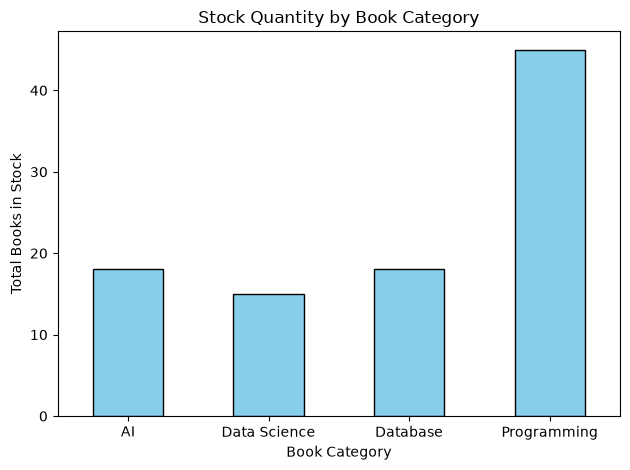

In [21]:
store.df.groupby("Category")["Stock_Quantity"].sum().plot(
    kind="bar",
    color="skyblue",
    edgecolor="black"
)

plt.title("Stock Quantity by Book Category")
plt.xlabel("Book Category")
plt.ylabel("Total Books in Stock")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

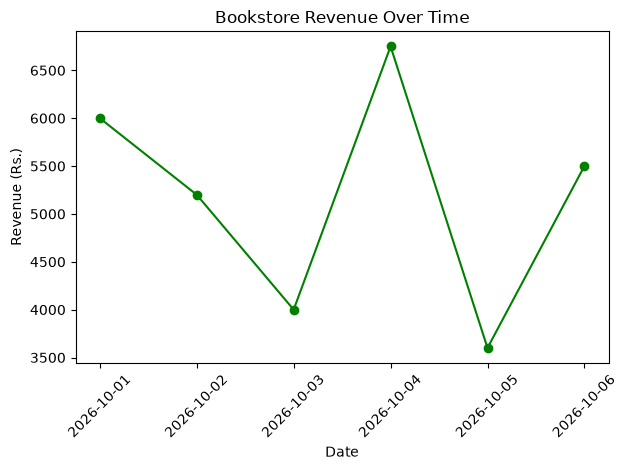

In [22]:
plt.plot(
    store.df["Date"],
    store.df["Price"] * store.df["Units_Sold"],
    marker="o",
    color="green"
)

plt.title("Bookstore Revenue Over Time")
plt.xlabel("Date")
plt.ylabel("Revenue (Rs.)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

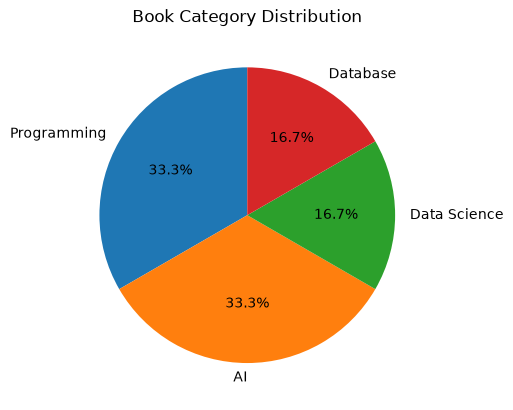

In [23]:
plt.pie(
    store.df["Category"].value_counts(),
    labels=store.df["Category"].value_counts().index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Book Category Distribution")
plt.show()

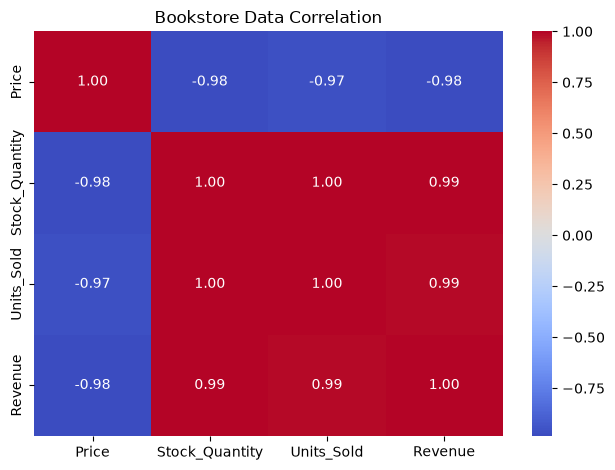

In [24]:
correlation = store.df[
    ["Price", "Stock_Quantity", "Units_Sold"]
].copy()

correlation["Revenue"] = (
    store.df["Price"] * store.df["Units_Sold"]
)

correlation = correlation.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Bookstore Data Correlation")
plt.tight_layout()
plt.show()